# Practical 4: Polynomial Regression and the Bias-Variance Trade-off

**Aim:** Fit polynomial regression with different degrees and see how model complexity affects accuracy (underfitting vs overfitting).

**Dataset:** Auto MPG (built into seaborn): horsepower of a car vs its fuel efficiency (mpg). The relationship is curved, so a straight line is not enough.

**Steps:** 1) Load and plot  2) Split and scale  3) Fit degrees 1, 2, 3, 5, 8, 12  4) Plot the curves  5) Plot train error vs test error

## Step 1: Load and look at the data

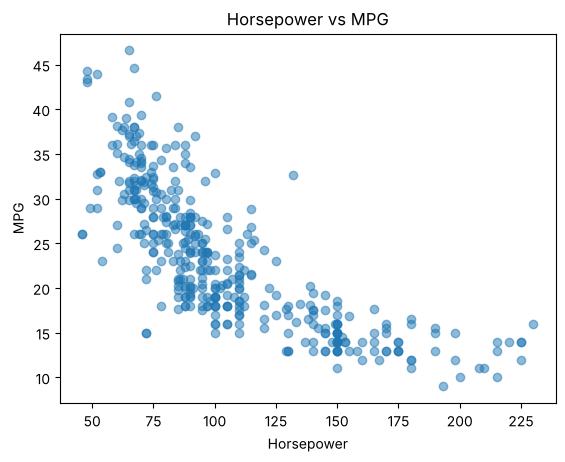

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

mpg = sns.load_dataset("mpg")
mpg = mpg.dropna(subset=["horsepower"])      # remove rows with missing horsepower

X = mpg[["horsepower"]]    # input (2D)
y = mpg["mpg"]             # target

plt.scatter(X, y, alpha=0.5)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")
plt.show()

**How to read:** each dot is a car. MPG falls as horsepower rises, but it is a **curve** (steep at first, then flatter), not a straight line. So we expect a straight line to underfit.

## Step 2: Split and scale

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

# Scale so that large powers (x to the 12) do not become huge numbers
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (274, 1)  Test: (118, 1)


## Step 3: Fit polynomials of different degrees
A degree-3 polynomial is `y = b0 + b1*x + b2*x² + b3*x³`. We create the extra columns x², x³ ... with `PolynomialFeatures` and then use ordinary linear regression.

In [3]:
degrees = [1, 2, 3, 5, 8, 12]
models = {}
rows = []

for d in degrees:
    poly = PolynomialFeatures(degree=d)
    X_train_poly = poly.fit_transform(X_train)   # adds x^2, x^3, ...
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    models[d] = (poly, model)

    train_mse = mean_squared_error(y_train, model.predict(X_train_poly))
    test_mse = mean_squared_error(y_test, model.predict(X_test_poly))
    test_r2 = r2_score(y_test, model.predict(X_test_poly))
    rows.append([d, round(train_mse, 2), round(test_mse, 2), round(test_r2, 3)])

pd.DataFrame(rows, columns=["Degree", "Train MSE", "Test MSE", "Test R2"])

,Degree,Train MSE,Test MSE,Test R2
0,1,23.07,26.19,0.606
1,2,18.82,19.80,0.702
2,3,18.79,19.76,0.703
3,5,18.16,19.48,0.707
4,8,17.67,19.63,0.705
5,12,17.72,20.02,0.699


## Step 4: Plot the fitted curves

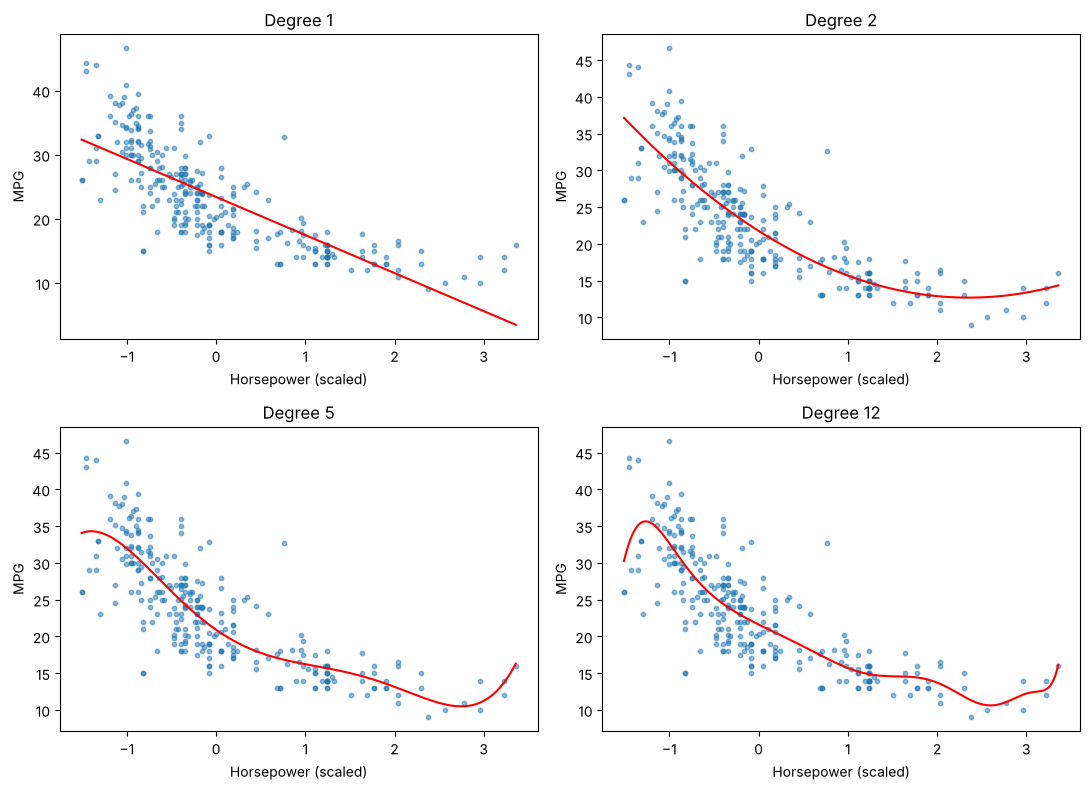

In [4]:
x_line = np.linspace(X_train.min(), X_train.max(), 300).reshape(-1, 1)

plt.figure(figsize=(11, 8))
for i, d in enumerate([1, 2, 5, 12]):
    poly, model = models[d]
    plt.subplot(2, 2, i + 1)
    plt.scatter(X_train, y_train, s=10, alpha=0.5)
    plt.plot(x_line, model.predict(poly.transform(x_line)), color="red")
    plt.title("Degree " + str(d))
    plt.xlabel("Horsepower (scaled)")
    plt.ylabel("MPG")
plt.tight_layout()
plt.show()

**How to read:**
- **Degree 1 (straight line):** misses the bend, so the error is high. This is **underfitting** (high bias).
- **Degree 2:** follows the curve well. Good fit.
- **Degree 5 and 12:** the curve is wigglier and starts to chase individual points, especially at the edges. This is the start of **overfitting** (high variance).

## Step 5: Train error vs test error

Degree with the lowest test error: 6


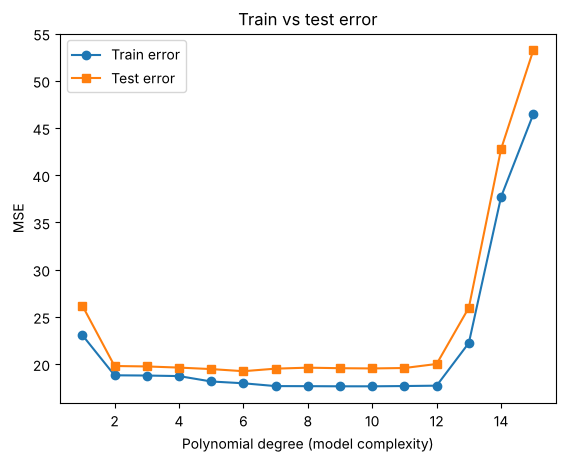

In [5]:
train_errors = []
test_errors = []
all_degrees = range(1, 16)

for d in all_degrees:
    poly = PolynomialFeatures(degree=d)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    model = LinearRegression().fit(X_train_poly, y_train)
    train_errors.append(mean_squared_error(y_train, model.predict(X_train_poly)))
    test_errors.append(mean_squared_error(y_test, model.predict(X_test_poly)))

best = list(all_degrees)[np.argmin(test_errors)]
print("Degree with the lowest test error:", best)

plt.plot(all_degrees, train_errors, marker="o", label="Train error")
plt.plot(all_degrees, test_errors, marker="s", label="Test error")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("MSE")
plt.title("Train vs test error")
plt.legend()
plt.show()

**How to read (important for the viva):**
- **Train error** (blue) keeps going down as the degree increases, because a more flexible model fits the training points better.
- **Test error** (orange) drops a lot from degree 1 to 2, then stays almost flat. The lowest point is the best degree (degree 6 in my run), but degrees 2 to 12 are nearly the same, so **degree 2 is the simplest good choice**.
- The gap between the two lines slowly grows with the degree: that is overfitting starting.
- On this dataset (one feature, about 270 training points) the test curve is only a *shallow* U. With less data or more noise the right side would rise sharply. Say this honestly in the viva.

## Conclusion
Degree 1 underfits (high bias). Degree 2 captures the curve. Higher degrees add very little on test data and risk overfitting (high variance). The best model is the simple one with low test error, found by looking at test error, never training error.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is polynomial regression?**
Regression where the relationship between x and y is modelled as an n-th degree polynomial: $y = b_0 + b_1x + b_2x^2 + \dots + b_dx^d$. It captures curved relationships.

**Q2. Why is it called a linear model even though the curve is non-linear?**
Because it is linear in the parameters $b_0, b_1, \dots$. We transform x into $x, x^2, x^3$ and fit an ordinary linear regression on these new features.

**Q3. What does `PolynomialFeatures(degree=2)` do?**
For one input x it creates $[1, x, x^2]$. For two inputs (a, b) it creates $[1, a, b, a^2, ab, b^2]$, including interaction terms. `include_bias=False` drops the constant column because the regression already has an intercept.

**Q4. When do you use polynomial regression?**
When a scatter plot shows a curved relationship that a straight line cannot capture.

**Q5. What is bias?**
Error from wrong or overly simple assumptions in the model. High bias causes underfitting.

**Q6. What is variance?**
Error from sensitivity to small changes in the training data. High variance causes overfitting because the model learns noise.

**Q7. Explain the bias-variance trade-off.**
Increasing model complexity lowers bias but raises variance. Expected test error = Bias² + Variance + Irreducible noise. The goal is the sweet spot of minimum total error.

**Q8. What is underfitting?**
The model is too simple to capture the pattern. Both training and test errors are high.

**Q9. What is overfitting?**
The model fits training data (and its noise) too closely. Training error is very low but test error is high.

**Q10. How do you detect overfitting?**
A large gap between training performance and test performance. Learning curves and cross-validation also show it.

**Q11. How do you reduce overfitting?**
Lower the polynomial degree, get more data, use regularisation (Ridge/Lasso), use cross-validation for model selection, remove features, or use early stopping.

**Q12. How do you choose the best degree?**
Compare test or cross-validation error for several degrees and choose the lowest, preferring the simplest degree when scores are similar.

**Q13. What is irreducible error?**
Noise inherent in the data that no model can remove.

**Q14. What happens to the number of features as the degree grows?**
It grows very quickly with multiple inputs (combinatorially), which raises computation and the risk of overfitting.

**Q15. Why scale features before polynomial regression?**
$x^{12}$ creates huge values and numerical instability. Scaling keeps the numbers manageable.

**Q16. Can training R² alone judge the model?**
No. Training R² always rises with degree. Judge on test data or cross-validation.

**Q17. Can polynomial regression extrapolate well?**
No. Outside the training range, high-degree polynomials give extreme, unreliable predictions.

**Q18. What is Runge's phenomenon?**
High-degree polynomials oscillate wildly near the edges of the data range, which is why the high-degree curve swings at the ends.

**Q19. What is the difference between polynomial regression and linear regression?**
Linear regression fits a straight line (or hyperplane). Polynomial regression fits a curve by adding powers of the inputs as extra features. Linear regression is polynomial regression of degree 1.

**Q20. Is polynomial regression a parametric model?**
Yes; the number of parameters is fixed by the degree.

**Q21. Which metrics did you use?**
MSE and R² on both train and test sets, plus cross-validated MSE.

## B. Questions about the graphs

**G1. What does the scatter plot of horsepower vs MPG show?**
A negative, curved relationship: MPG decreases as horsepower increases, steeply at first and then flattening. This is why a straight line is not enough.

**G2. What does the degree 1 curve look like and what does it mean?**
A straight line that misses the curvature. Both train and test errors are high, so it underfits (high bias, low variance).

**G3. What does a very high degree curve look like?**
A wiggly curve that bends to follow individual points and can swing wildly at the edges. Train error is very low but test error is not better, so it overfits (low bias, high variance).

**G4. Explain the train/test error versus degree graph.**
Train error keeps falling as degree rises. Test error falls first, reaches a minimum (the best degree) and then flattens or rises. The gap between the two lines widens with overfitting.

**G5. Where is the best model on that graph?**
At the degree with the lowest test (or cross-validation) error, where bias and variance are balanced. In my run the test error is lowest at degree 6 and the CV error at degree 7, but degree 2 is almost as good, so I prefer the simpler model.

**G5b. Your test-error curve is almost flat after degree 2. Why is there no clear U-shape?**
The dataset has one input feature and about 270 training points, so even a high-degree polynomial is well constrained in the dense region and the test split changes little. The overfitting shows up where data is sparse (the edges), which is why cross-validation error rises and the bootstrap variance explodes at high degrees. With less data or more noise the U-shape on the test curve would be much sharper.

**G6. Why does the curve swing at the ends for high degrees?**
High-degree terms grow very fast outside the dense data region, so small coefficient changes cause large swings (Runge's phenomenon). Few data points at the edges also give the model little to constrain it.

## C. Code questions

**C3. Why `np.linspace` and `reshape(-1, 1)`?**
To create a smooth grid of x values (one column) for drawing the fitted curve, since scikit-learn expects a 2-D array.

**C4. Why do we reshape X to 2-D?**
scikit-learn features must be shaped (n_samples, n_features).